In [2]:
import os
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter
from typing import Dict, List, Optional, Tuple

In [464]:
METRICS = ["dci", "factorvae", "mig", "mse", "lpips"]

SAVE_FIGS = True
OUTDIR = "analysis_plots"
os.makedirs(OUTDIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="talk")

In [465]:
def final_valid_value(df: pd.DataFrame, metric: str):
    """Return final valid (non-NaN) value from df[metric], else None."""
    if df is None or df.empty or metric not in df.columns:
        return None
    s = df[metric].dropna()
    if len(s) == 0:
        return None
    v = s.iloc[-1]
    try:
        return float(v)
    except Exception:
        return None

# ----------------------------------------------------
# 1. Walk the directory and gather metrics per model_setting
#    Folder naming convention:
#      "<seed><model_setting>"
#    e.g. "0shapes3d_v_cosine_sech"
# ----------------------------------------------------
results = defaultdict(list)  # final values per run
curves = defaultdict(list)   # full curves per run (nimgs + metrics)

for folder in os.listdir(ROOT):
    folder_path = os.path.join(ROOT, folder)
    if not os.path.isdir(folder_path):
        continue

    # expect folder names like "0shapes3d_v_cosine_sech"
    try:
        seed = int(folder[0])
        model_setting = folder[1:]
    except Exception:
        # skip folders not matching the pattern
        continue

    metrics_path = os.path.join(folder_path, "metrics.csv")
    if not os.path.exists(metrics_path):
        print(f"Skipping {folder}, no metrics.csv")
        continue

    try:
        df = pd.read_csv(metrics_path)
    except Exception as e:
        print(f"Skipping {folder}, failed to read metrics.csv: {e}")
        continue

    # store final values robustly (handles empty cols / NaNs)
    entry = {}
    for m in METRICS:
        entry[m] = final_valid_value(df, m)

    # optionally skip runs with no usable values
    if all(entry[m] is None for m in METRICS):
        print(f"Skipping {folder}, metrics.csv has no usable metric values")
        continue

    results[model_setting].append(entry)

    # store full curve for training-efficiency plot
    needed_cols = ["nimgs"] + [m for m in METRICS if m in df.columns]
    if "nimgs" in df.columns:
        curves[model_setting].append(df[needed_cols].copy())

In [466]:
def smooth_curve(y, window=9, poly=3):
    """Savitzky–Golay smoothing with safe window handling."""
    n = len(y)
    if n < 3:
        return y
    w = min(window, n if n % 2 == 1 else n - 1)
    if w < 3:
        return y
    return savgol_filter(y, window_length=w, polyorder=min(poly, w - 1))


def parse_run_name_seedprefix(run_name: str) -> Tuple[str, Optional[int]]:
    """
    Parse '{seed}v_cosine_sech_dynamic1' -> (model_class, seed).

    We treat everything AFTER the first 'v' as the model class identifier.

    Example:
        '0v_cosine_sech_dynamic1' -> model_class='v_cosine_sech_dynamic1', seed=0
        '3v_cosine_sech_dynamic1' -> model_class='v_cosine_sech_dynamic1', seed=3

    So {0-5}v_cosine_sech_dynamic1 are grouped together.
    """
    m = re.match(r"(?P<seed>\d+)v(?P<rest>.+)", run_name)
    if not m:
        # fallback: no seed prefix, treat whole name as model_class
        return run_name, None
    seed = int(m.group("seed"))
    rest = m.group("rest")
    model_class = "v" + rest
    return model_class, seed


def nth_difference(y: np.ndarray, n: int = 1) -> np.ndarray:
    """Nth-order forward finite differences. Length shrinks by n."""
    y = np.asarray(y, dtype=float)
    if n <= 0:
        return y
    if y.size <= n:
        return np.full_like(y, np.nan)
    return np.diff(y, n=n)


def pad_front(arr: np.ndarray, n: int) -> np.ndarray:
    """Pad with n NaNs at the front to keep same length as original."""
    if n <= 0:
        return arr
    return np.concatenate([np.full(n, np.nan), arr])


def load_dynamic_range(config_dir: str):
    """
    Look for a single *.json config in config_dir and read dynamic_min/max.
    Returns (dynamic_min, dynamic_max) or (None, None) if not found.
    """
    try:
        cfg_paths = glob.glob(os.path.join(config_dir, "*.json"))
        if not cfg_paths:
            return None, None
        import json
        with open(cfg_paths[0], "r") as f:
            cfg = json.load(f)
        w_cfg = cfg.get("weighting", {})
        return w_cfg.get("dynamic_min"), w_cfg.get("dynamic_max")
    except Exception:
        return None, None


def _safe_read_metrics(metrics_path: str) -> Optional[pd.DataFrame]:
    """Read metrics.csv robustly; return None if missing/empty/bad."""
    try:
        df = pd.read_csv(metrics_path)

        # skip header-only / empty metrics files
        if df is None or df.empty:
            return None

        # require nimgs for sorting/aligning
        if "nimgs" not in df.columns:
            return None

        df = df.sort_values("nimgs")
        return df
    except Exception:
        return None


def smooth_tail(x, y, after, window=31, poly=3):
    if after is None:
        return y
    y = y.copy()
    m = x >= after
    if m.sum() >= 3:
        y[m] = smooth_curve(y[m], window=window, poly=poly)
    return y


def plot_dis_vs_recon_per_model_class(
    base_dir: str,
    dis_col: str = "dci",
    lpips_col: str = "lpips",
    smooth: bool = True,
    window: int = 9,
    poly: int = 3,
    overlay_mean: bool = True,
    cmap_name: str = "viridis",
    out_dir: str = "analysis_plots/dis_vs_recon_by_model",
    file_ext: str = "pdf",
    show: bool = False,
    diff_order: int = 1,
    figsize = (7, 7),
    max_nimgs: float | None = None,
    tail_smooth_after: float | None = None,  # e.g. 150_000
    tail_window: int = 31,
    tail_poly: int = 3,
):
    """
    For each model class, generate ONE figure with two panels:
        (left)  dis vs mse
        (right) dis vs lpips

    Each seed/run is a trajectory line through checkpoints (nimgs).
    Line colour is determined by the run's FINAL disentanglement metric (dis_col),
    normalised WITHIN the model class (so colours are comparable within each figure).

    Optionally overlays the mean trajectory across seeds in black dashed.
    """
    os.makedirs(out_dir, exist_ok=True)

    run_dirs = [
        d for d in os.listdir(base_dir)
        if os.path.isdir(os.path.join(base_dir, d))
    ]
    run_dirs = sorted(run_dirs)
    if not run_dirs:
        raise RuntimeError(f"No run directories found in {base_dir}")

    # ---------- group runs by model_class ----------
    groups: Dict[str, List[str]] = {}
    seeds_by_run: Dict[str, Optional[int]] = {}
    for run_name in run_dirs:
        model_class, seed = parse_run_name_seedprefix(run_name)
        groups.setdefault(model_class, []).append(run_name)
        seeds_by_run[run_name] = seed

    # ---------- load metrics per run ----------
    per_run_df: Dict[str, pd.DataFrame] = {}
    for run_name in run_dirs:
        metrics_path = os.path.join(base_dir, run_name, "metrics.csv")
        if not os.path.exists(metrics_path):
            continue
        df = _safe_read_metrics(metrics_path)
        if df is None:
            continue
        per_run_df[run_name] = df

    # ---------- plot per model class ----------
    for model_class, runs in sorted(groups.items()):
        # valid runs: have metrics and required columns
        valid_runs = []
        for r in runs:
            df = per_run_df.get(r)
            if df is None:
                continue
            if not {dis_col, lpips_col}.issubset(df.columns):
                continue
            valid_runs.append(r)

        if len(valid_runs) == 0:
            continue

        # title label info (dynamic range if available)
        cfg_dir = os.path.join(base_dir, valid_runs[0], "configs")
        dyn_min, dyn_max = load_dynamic_range(cfg_dir)
        if dyn_min is not None and dyn_max is not None:
            title = f"{model_class}  [dynamic {dyn_min}, {dyn_max}]"
        else:
            title = model_class

        # compute final disentanglement per run (for colouring)
        final_dis_by_run: Dict[str, float] = {}
        for r in valid_runs:
            df = per_run_df[r]
            dis = df[dis_col].values.astype(float)
            if smooth:
                dis = smooth_curve(dis, window=window, poly=poly)
            final_dis_by_run[r] = float(dis[-1])

        dis_vals = np.array(list(final_dis_by_run.values()))
        d_min, d_max = float(dis_vals.min()), float(dis_vals.max())
        if np.isclose(d_min, d_max):
            d_max = d_min + 1e-6  # avoid zero range

        norm = plt.Normalize(vmin=0, vmax=0.65)
        cmap = plt.get_cmap(cmap_name)

        fig, axes = plt.subplots(1, 1, figsize=figsize)

        # For mean overlay we need a reference grid
        ref_nimgs = None
        dis_stack = []
        lp_stack = []

        # Plot each seed trajectory coloured by its final dis score
        def _sort_key(run_name: str):
            s = seeds_by_run.get(run_name)
            return (s is None, s if s is not None else 999999, run_name)

        for r in sorted(valid_runs, key=_sort_key):
            df = per_run_df[r]

            x = df["nimgs"].values.astype(float)
            dis = df[dis_col].values.astype(float)
            lp = df[lpips_col].values.astype(float)

            if max_nimgs is not None:
                m = x <= max_nimgs
                x, dis, lp = x[m], dis[m], lp[m]
                if len(x) < 2:
                    continue

            if smooth:
                dis = smooth_curve(dis, window=window, poly=poly)
                lp = smooth_curve(lp, window=window, poly=poly)

                dis = smooth_tail(x, dis, tail_smooth_after, window=tail_window, poly=tail_poly)
                lp  = smooth_tail(x, lp,  tail_smooth_after, window=tail_window, poly=tail_poly)

            colour = cmap(norm(final_dis_by_run[r]))

            axes.plot(
                lp,
                dis,
                linewidth=1.8,
                alpha=0.75,
                color=colour,
            )

            # stacks for mean overlay (interpolate to reference grid)
            if overlay_mean:
                if ref_nimgs is None:
                    ref_nimgs = x
                    dis_i, lp_i = dis, lp
                else:
                    dis_i = np.interp(ref_nimgs, x, dis)
                    lp_i = np.interp(ref_nimgs, x, lp)

                dis_stack.append(dis_i)
                lp_stack.append(lp_i)

        # Overlay mean trajectory (black dashed)
        if overlay_mean and len(dis_stack) > 0:
            dis_mean = np.mean(np.stack(dis_stack, axis=0), axis=0)
            lp_mean = np.mean(np.stack(lp_stack, axis=0), axis=0)

            axes.plot(
                lp_mean,
                dis_mean,
                color="black",
                linewidth=3.0,
                linestyle="--",
                alpha=0.95,
                label="mean",
            )

            # Optional: show only "mean" in a tiny legend
            ax_lp.legend(loc="best", fontsize=8, frameon=True)

        axes.set_xlim(left=-0.01, right=0.6)
        axes.set_ylim(bottom=-0.01, top=0.65)
        axes.set_xlabel(lpips_col)
        axes.set_ylabel(dis_col)
        axes.set_title(model_class)
        axes.grid(True, linestyle="--", alpha=0.3)

        # Colourbar (final dis_col) for this model-class figure
        sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
        sm.set_array([])
        cbar = fig.colorbar(
            sm,
            ax=axes,
            fraction=0.046,
            pad=0.04,
        )

        if show:
            plt.tight_layout()
        else:
            safe_name = re.sub(r"[^a-zA-Z0-9_\-]+", "_", model_class)
            out_path = os.path.join(out_dir, f"{safe_name}__{dis_col}_vs_recon.{file_ext}")
            fig.savefig(out_path, dpi=200, bbox_inches="tight")
            plt.close(fig)
            print(f"Saved {out_path}")

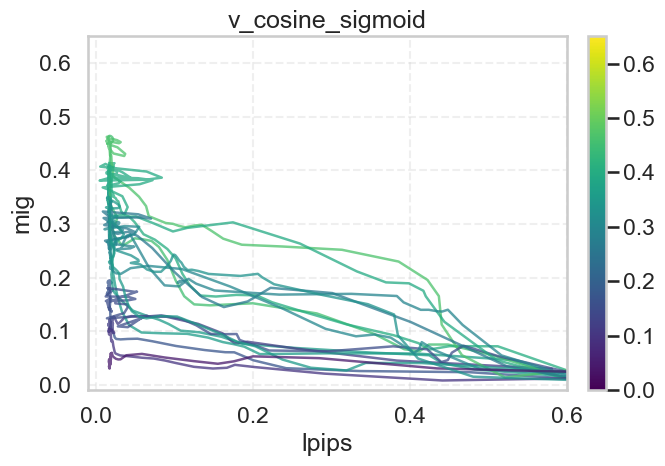

In [467]:
# ROOT = "ckpts/vdmpp/shapes3d_low_discrep..."
# ROOT = "ckpts/vdmpp/shapes3d_early_stage/..."

# ROOT = "ckpts/vdmpp_deep/shapes3d/"
# ROOT = "ckpts/vdmpp_deep_longer/shapes3d/"
# ROOT = "ckpts/vdmpp_deep_longer_stable/shapes3d/"
ROOT = "ckpts/vdmpp_deep_longer_stable2/shapes3d/"

plot_dis_vs_recon_per_model_class(
    ROOT,
    dis_col="mig",
    lpips_col="lpips",
    out_dir="analysis_plots/dis_vs_recon_by_model",
    file_ext="pdf",
    show=True,
    overlay_mean=False,
    window=5,
    diff_order=0,
    figsize=(7, 5),
    max_nimgs=5120000,
    tail_smooth_after=1500000,
    tail_window=30,
    tail_poly=5,
)

In [468]:
def load_data(
    base_dir: str,
    dis_col: str = "dci",
    lpips_col: str = "lpips",
):
    """
    For each model class, generate ONE figure with two panels:
        (left)  dis vs mse
        (right) dis vs lpips

    Each seed/run is a trajectory line through checkpoints (nimgs).
    Line colour is determined by the run's FINAL disentanglement metric (dis_col),
    normalised WITHIN the model class (so colours are comparable within each figure).

    Optionally overlays the mean trajectory across seeds in black dashed.
    """
    run_dirs = [
        d for d in os.listdir(base_dir)
        if os.path.isdir(os.path.join(base_dir, d))
    ]
    run_dirs = sorted(run_dirs)
    if not run_dirs:
        raise RuntimeError(f"No run directories found in {base_dir}")

    # ---------- group runs by model_class ----------
    groups: Dict[str, List[str]] = {}
    seeds_by_run: Dict[str, Optional[int]] = {}
    for run_name in run_dirs:
        model_class, seed = parse_run_name_seedprefix(run_name)
        groups.setdefault(model_class, []).append(run_name)
        seeds_by_run[run_name] = seed

    # ---------- load metrics per run ----------
    per_run_df: Dict[str, pd.DataFrame] = {}
    per_run_debug = {}
    for run_name in run_dirs:
        metrics_path = os.path.join(base_dir, run_name, "metrics.csv")
        debug_path = os.path.join(base_dir, run_name, "debug.csv")
        if not os.path.exists(metrics_path):
            continue
        if not os.path.exists(debug_path):
            continue
        df = _safe_read_metrics(metrics_path)
        df_debug = _safe_read_metrics(debug_path)
        if df is None:
            continue
        if df_debug is None:
            continue
        per_run_df[run_name] = df
        per_run_debug[run_name] = df_debug

    return per_run_df, per_run_debug

In [469]:
import numpy as np
from scipy.optimize import curve_fit

def dynamics_model_to_floor(t, inf, A, k):
    # increases to inf (floor) if A > 0
    return inf + A * np.exp(-k * t)

def dynamics_model_to_plateau(t, inf, A, k):
    # increase to inf (plateau) if A > 0
    return inf - A * np.exp(-k * t)

def dynamics_model_log_growth(t, y0, a, k):
    # MIG(t) = y0 + a * log(1 + k t)
    return y0 + a * np.log1p(k * t)

def log_half_life(t, y0, a, k):
    """
    "Half-life" for log-growth: the time t_half to reach halfway between
    MIG(0)=y0 and MIG(1)=y0 + a*log(1+k).

    i.e. MIG(t_half) - y0 = 0.5 * (MIG(1) - y0)
    => log(1+k t_half) = 0.5 * log(1+k)
    => t_half = ((1+k)**0.5 - 1) / k
    """
    k = float(k)
    if k <= 0:
        return np.nan
    return (np.sqrt(1.0 + k) - 1.0) / k

def fit_lpips(t, metric):
    t = np.asarray(t, float)
    metric = np.asarray(metric, float)

    tail = metric[int(0.8 * len(metric)):] if len(metric) >= 5 else metric
    inf0 = float(np.median(tail))
    A0 = float(max(metric[0] - inf0, 1e-6))     # LPIPS(0) - floor
    k0 = 5.0

    p0 = [inf0, A0, k0]
    bounds = ([0.0, 0.0, 0.0], [np.inf, np.inf, np.inf])

    popt, _ = curve_fit(exp_to_floor, t, metric, p0=p0, bounds=bounds, maxfev=100000)
    return {f"inf_lpips": popt[0], f"A_lpips": popt[1], f"k_lpips": popt[2]}

def fit_mig(t, metric):
    t = np.asarray(t, float)
    metric = np.asarray(metric, float)

    tail = metric[int(0.8 * len(metric)):] if len(metric) >= 5 else metric
    inf0 = float(np.median(tail))
    B0 = float(max(inf0 - metric[0], 1e-6))     # plateau - MIG(0)
    k0 = 2.0

    p0 = [inf0, B0, k0]
    bounds = ([-np.inf, 0.0, 0.0], [np.inf, np.inf, np.inf])

    popt, _ = curve_fit(exp_to_plateau, t, metric, p0=p0, bounds=bounds, maxfev=100000)
    return {f"inf_mig": popt[0], f"A_mig": popt[1], f"k_mig": popt[2], "r0": popt[1] * popt[2], "tau": 1 / popt[2]}

def fit_run(nimgs, lpips, mig, nimgs_max=9984000, nimgs_min=12800):
    t = (np.asarray(nimgs) - nimgs_min) / (nimgs_max - nimgs_min + 1e-12)
    t = np.clip(t, 0.0, 1.0)

    lp = fit_lpips(t, lpips)
    mg = fit_mig(t, mig)
    # mg = fit_mig_log(t, mig)
    return {**lp, **mg}

import numpy as np

def tail_median(x, frac=0.8):
    x = np.asarray(x, float)
    start = int(frac * len(x))
    return float(np.median(x[start:])) if len(x) >= 5 else float(np.median(x))

def ttc_threshold(nimgs, metric, thr, direction="le"):
    """Return first nimgs where metric crosses threshold."""
    nimgs = np.asarray(nimgs)
    metric = np.asarray(metric, float)
    if direction == "le":
        idx = np.where(metric <= thr)[0]
    else:
        idx = np.where(metric >= thr)[0]
    return float(nimgs[idx[0]]) if len(idx) else np.nan

def ttc_fraction_of_final(nimgs, metric, final_value, frac=0.8, increasing=True):
    """Time to reach y0 + frac*(final-y0) for increasing metrics, or analogous for decreasing."""
    nimgs = np.asarray(nimgs)
    metric = np.asarray(metric, float)
    y0 = float(metric[0])
    yf = float(final_value)

    if increasing:
        target = y0 + frac * (yf - y0)
        idx = np.where(metric >= target)[0]
    else:
        target = y0 - frac * (y0 - yf)
        idx = np.where(metric <= target)[0]

    return float(nimgs[idx[0]]) if len(idx) else np.nan

In [470]:
per_run_df, per_run_debug = load_data(ROOT, dis_col='mig')

all_coeffs = []

for run, metrics in per_run_df.items():
    run_name = run.split("_")
    weighting = run_name[-1]
    
    nimgs = metrics.nimgs.values
    lpips = metrics.lpips.values
    mig = metrics.mig.values

    coeffs = fit_run(nimgs, lpips, mig)
    coeffs['mig_convergence'] = np.median(mig[int(0.8 * len(mig)):] if len(mig) >= 5 else mig)
    coeffs['lpips_convergence'] = np.median(lpips[int(0.8 * len(lpips)):] if len(lpips) >= 5 else lpips)
    coeffs['weighting'] = weighting
    coeffs['run_name'] = run_name[0]
    
    # debug_df = per_run_debug[run]
    # coeffs['grads_ratio'] = (debug_df[debug_df.nimgs < 200000].window_enc_mean / debug_df[debug_df.nimgs < 200000].window_dec_mean).mean()
    # mask = (debug_df.nimgs >= 50000) & (debug_df.nimgs < 200000)
    # coeffs['grads_enc'] = debug_df[mask].window_enc_mean.mean()

    coeffs["mig_final"] = tail_median(mig)
    coeffs["lpips_final"] = tail_median(lpips)
    
    coeffs["ttc_lpips"] = ttc_threshold(nimgs, lpips, thr=0.03, direction="le")
    coeffs["ttc_mig"]   = ttc_fraction_of_final(nimgs, mig, final_value=coeffs["mig_final"], frac=0.8, increasing=True)
    
    all_coeffs.append(coeffs)

df = pd.DataFrame(all_coeffs)

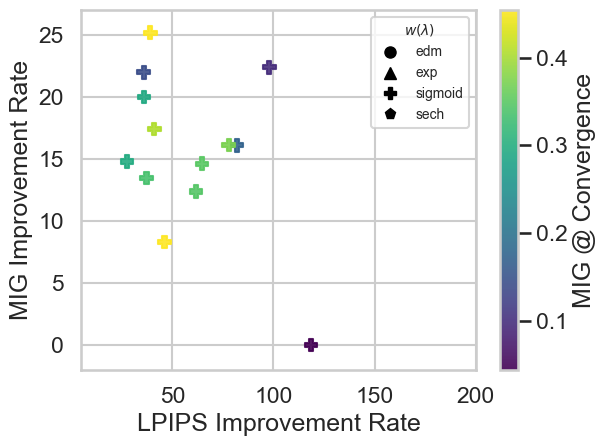

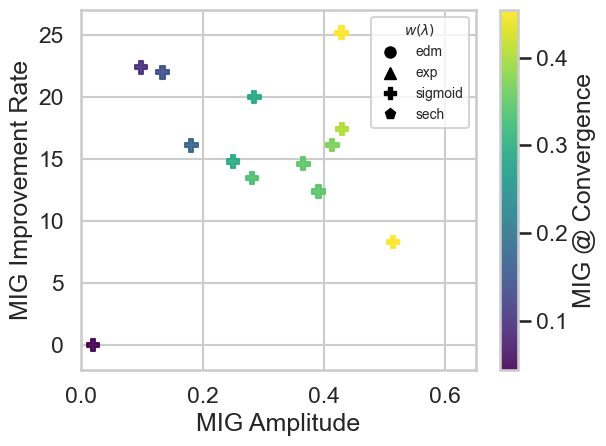

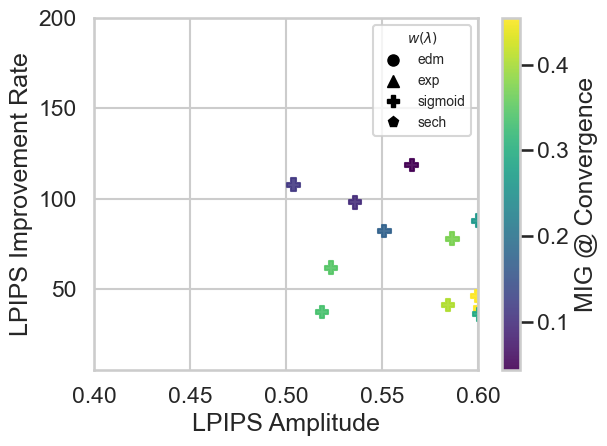

In [471]:
import pandas as pd
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

marker = {
    'edm': 'o',
    'exp': '^',
    'sigmoid': 'P',
    'sech': 'p',
}
titles = {
    'k_lpips': 'LPIPS Improvement Rate',
    'k_mig': 'MIG Improvement Rate',
    'A_lpips': 'LPIPS Amplitude',
    'A_mig': 'MIG Amplitude',
    'ttc_lpips': 'LPIPS Time to Converge',
    'ttc_mig': 'MIG Time to Converge',
    'tau': 'Characteristic Timescale',
    'r0': 'Early Improvement Rate',
}
lims = {
    'k_lpips': (5, 200), # (5, 110),
    'k_mig': (-2, 27), # (-2, 25),
    'A_lpips': (0.4, 0.60),
    'A_mig': (0, 0.65),
    'ttc_lpips': (0, 3500000),
    'ttc_mig': (0, 4000000),
    'tau': (0, 0.3),
    'r0': (0, 20),
}

# def size3_from_lpips(lp, q=(0.33, 0.66), sizes=(120, 260, 520), invert=True):
#     """
#     3-band size mapping.
#     invert=True => smaller LPIPS -> larger marker (usually what you want).
#     """
#     lp = np.asarray(lp, float)
#     q1, q2 = np.nanquantile(lp, q)

#     # bins: 0 (low), 1 (mid), 2 (high)
#     bins = np.digitize(lp, [q1, q2])  # returns 0,1,2

#     if invert:
#         bins = 2 - bins  # low LPIPS -> bin 2 -> largest size

#     return np.array(sizes, dtype=float)[bins]]

from matplotlib.colors import TwoSlopeNorm

def plot_coeffs(df, x, y, c="mig", cmap="viridis"):
    for weighting, _df in df.groupby('weighting'):
        if c == "mig":
            c_series = _df.mig_convergence
            c_label = "MIG @ Convergence"
            norm = None
        elif c == "lpips":
            c_series = _df.lpips_convergence
            c_label = "LPIPS @ Convergence"
            norm = None
        elif "grads" in c:
            c_series = _df[c]
            c_label = "Early Gradients"
            norm = None #TwoSlopeNorm(vmin=0.04, vcenter=0.055, vmax=0.08)
            
        plt.scatter(
            _df[x],
            _df[y],
            c=c_series,
            # s=sizes,
            marker=marker[weighting],
            label=weighting,
            cmap=cmap,
            norm=norm,
            alpha=0.9,
        )
    
    plt.xlabel(titles[x])
    plt.ylabel(titles[y])
    plt.colorbar(label=c_label)
    plt.xlim(left=lims[x][0], right=lims[x][1])
    plt.ylim(bottom=lims[y][0], top=lims[y][1])
    
    handles = [
        Line2D([0], [0],
               marker=marker[w], linestyle="None",
               markerfacecolor="black", markeredgecolor="black",
               color="black", markersize=8, label=w)
        for w in marker
    ]
    plt.legend(handles=handles, title="$w(\lambda)$", fontsize=10, title_fontsize=10)
    plt.tight_layout()
    plt.show()


# plot_coeffs(df, 'A_mig', 'A_lpips', "mig")
# plot_coeffs(df, 'k_lpips', 'A_mig', "lpips")
# plot_coeffs(df, 'A_lpips', 'k_lpips', "mig")
# plot_coeffs(df, 'A_mig', 'k_mig', "lpips")
# plot_coeffs(df, 'A_mig', 'k_mig', "lpips")
# plot_coeffs(df, 'A_lpips', 'k_lpips', "mig")
# plot_coeffs(df, 'A_lpips', 'k_lpips', c="lpips", cmap="viridis")
# plot_coeffs(df, 'A_mig', 'k_mig', c="lpips", cmap="magma")
# plot_coeffs(df, 'A_mig', 'k_mig', c="grads_enc", cmap="coolwarm")

# plot_coeffs(df, 'ttc_mig', 'ttc_lpips', c="mig", cmap="viridis")
plot_coeffs(df, 'k_lpips', 'k_mig', "mig")
# plot_coeffs(df, 'A_mig', 'A_lpips', c="mig", cmap="viridis")
plot_coeffs(df, 'A_mig', 'k_mig', c="mig", cmap="viridis")
plot_coeffs(df, 'A_lpips', 'k_lpips', c="mig", cmap="viridis")
# plot_coeffs(df, 'tau', 'r0', c="mig", cmap="viridis")

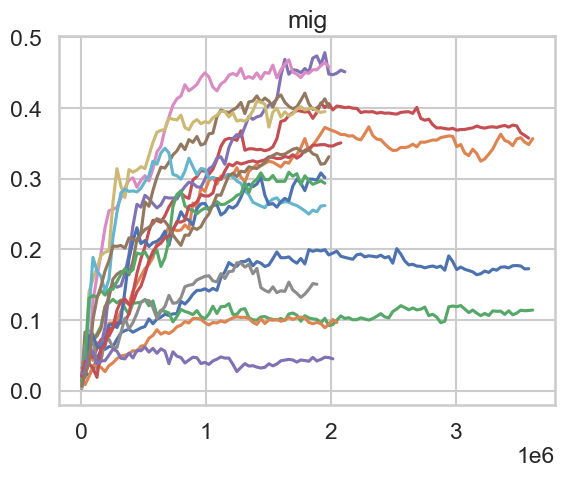

In [474]:
for k, v in per_run_df.items():
    try:
        x2 = per_run_df[k]['mig'] # [[0, *list(range(9, 87))]]
    except:
        continue
    plt.plot(per_run_df[k]['nimgs'].values, x2.values)
plt.title('mig')
plt.show()

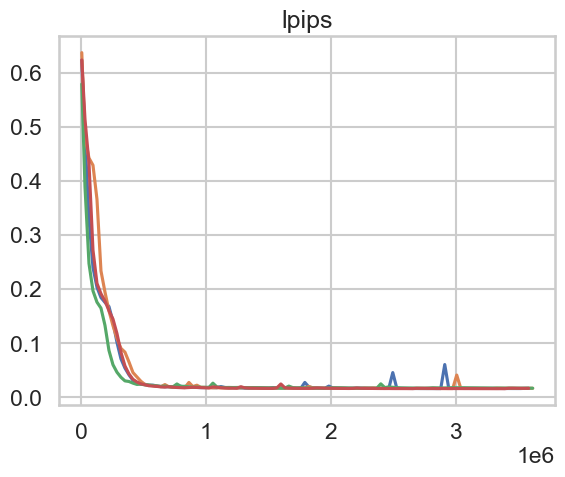

In [473]:
for k, v in per_run_df.items():
    try:
        x2 = per_run_df[k]['lpips'][[0, *list(range(10, 87))]]
    except:
        continue
    plt.plot(per_run_df[k]['nimgs'], per_run_df[k]['lpips'])
plt.title('lpips')
plt.show()

In [387]:
x2

0     0.560552
1     0.509045
2     0.480337
3     0.436288
4     0.422954
        ...   
81    0.019399
82    0.019654
83    0.020182
84    0.020014
85    0.019708
Name: lpips, Length: 86, dtype: float64

In [346]:
mask = (
    (df.weighting == "sigmoid") &
    (df.A_mig > 0.4) &
    (df.k_mig > 20)
)

df[mask]

,inf_lpips,A_lpips,k_lpips,inf_mig,A_mig,k_mig,mig_convergence,lpips_convergence,weighting,run_name,mig_final,lpips_final,ttc_lpips,ttc_mig
19,0.017135,0.538844,34.792030,0.469527,0.486633,20.695995,0.462853,0.016125,sigmoid,10v,0.462853,0.016125,768000.0,640000.0
23,0.018725,0.556790,71.186936,0.435584,0.429491,21.562285,0.427963,0.019461,sigmoid,11v,0.427963,0.019461,640000.0,768000.0
35,0.016813,0.532511,37.482469,0.555836,0.574746,24.620808,0.571416,0.017612,sigmoid,20v,0.571416,0.017612,640000.0,512000.0
63,0.016876,0.453831,39.381976,0.529761,0.533659,24.772529,0.500294,0.016816,sigmoid,33v,0.500294,0.016816,640000.0,640000.0


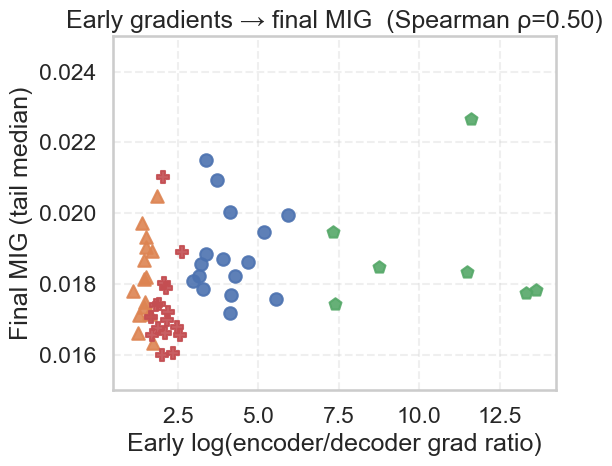

In [282]:
import numpy as np
import pandas as pd

per_run_df, per_run_debug = load_data(ROOT, dis_col='mig')

all_coeffs = []

EPS = 1e-12
EARLY_MIN = 40_000
EARLY_MAX = 200_000

for run, metrics in per_run_df.items():
    weighting = run.split("_")[-1]

    nimgs = metrics.nimgs.values
    lpips = metrics.lpips.values
    mig   = metrics.dci.values

    coeffs = fit_run(nimgs, lpips, mig)

    # convergence summaries (tail median)
    tail = slice(int(0.6 * len(mig)), None) if len(mig) >= 5 else slice(None)
    coeffs["mig_convergence"]   = float(np.median(mig[tail]))
    coeffs["lpips_convergence"] = float(np.median(lpips[tail]))
    coeffs["weighting"] = weighting

    # ---- early gradient features ----
    debug_df = per_run_debug[run]

    # early band mask
    mask = (debug_df.nimgs >= EARLY_MIN) & (debug_df.nimgs < EARLY_MAX)
    d = debug_df.loc[mask]

    # encoder mean in early window
    coeffs["grads_enc"] = float(d["window_enc_max"].mean())

    # encoder/decoder ratio (mean of per-step ratio) with epsilon
    ratio = d["window_dec_max"] / (d["window_enc_max"] + EPS)
    coeffs["grads_ratio"] = float(ratio.mean())

    # (optional but recommended) log-ratio: far more stable for correlations
    coeffs["log_grads_ratio"] = float(np.log(ratio + EPS).mean())

    all_coeffs.append(coeffs)

df = pd.DataFrame(all_coeffs)

import matplotlib.pyplot as plt
from scipy.stats import spearmanr

marker = {'edm': 'o', 'exp': '^', 'sigmoid': 'P', 'sech': 'p'}

xcol = "grads_ratio"     # or "grads_ratio"
# xcol = "grads_enc"
ycol = "lpips_convergence"     # or "inf_mig" if you prefer plateau from fit

plt.figure(figsize=(6, 5))
for w, g in df.groupby("weighting"):
    plt.scatter(
        g[xcol],
        g[ycol],
        marker=marker.get(w, "o"),
        alpha=0.9,
        label=w
    )

rho, p = spearmanr(df[xcol], df[ycol])
plt.title(f"Early gradients → final MIG  (Spearman ρ={rho:.2f})")
plt.xlabel("Early log(encoder/decoder grad ratio)")
plt.ylabel("Final MIG (tail median)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.ylim(bottom=0.015, top=0.025)
# plt.legend(title="$w(\\lambda)$")
plt.tight_layout()
plt.show()

In [ ]:
def delayed_exp(t, A, k, t0):
    tp = np.maximum(0.0, t - t0)
    return A*np.exp(-k*tp)

def lpips_two_stage(t, floor, A1, k1, A2, k2, t2):
    # early decay + later decay starting at t2
    return floor + A1*np.exp(-k1*t) + delayed_exp(t, A2, k2, t2)

def logistic_rise(t, low, high, k, t0):
    # rises from low to high around t0 with steepness k
    return low + (high - low) / (1.0 + np.exp(-k*(t - t0)))